In [1]:

from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\S_Gayathri\skill-gap-analyzer")
DATA_DIR = PROJECT_DIR / "data"
REPORTS_DIR = PROJECT_DIR / "reports"
PROCESSED_DIR = DATA_DIR / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project paths initialized successfully!")
print("Processed data directory:", PROCESSED_DIR)


Project paths initialized successfully!
Processed data directory: C:\Users\S_Gayathri\skill-gap-analyzer\data\processed


In [2]:

resumes = pd.read_csv(
    DATA_DIR / "resumes" / "Resume" / "Resume.csv",
    low_memory=False
)

jobs = pd.read_csv(
    DATA_DIR / "job_postings" / "postings.csv",
    nrows=20_000,
    low_memory=False
)

job_skills = pd.read_csv(
    DATA_DIR / "job_postings" / "jobs" / "job_skills.csv",
    low_memory=False
)

occupations = pd.read_excel(
    DATA_DIR / "onet" / "db_31_0_excel" / "Occupation Data.xlsx"
)

essential_skills = pd.read_excel(
    DATA_DIR / "onet" / "db_31_0_excel" / "Essential Skills.xlsx"
)

software_skills = pd.read_excel(
    DATA_DIR / "onet" / "db_31_0_excel" / "Software Skills.xlsx"
)

print("All datasets loaded successfully!")
print("Resumes:", resumes.shape)
print("Job postings sample:", jobs.shape)
print("Job skills:", job_skills.shape)
print("Occupations:", occupations.shape)
print("Essential skills:", essential_skills.shape)
print("Software skills:", software_skills.shape)


All datasets loaded successfully!
Resumes: (2484, 4)
Job postings sample: (20000, 31)
Job skills: (213768, 2)
Occupations: (1016, 3)
Essential skills: (18200, 15)
Software skills: (31821, 7)


In [3]:

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.-]+@[\w.-]+\.\w+\b", " ", text)
    text = re.sub(r"[^A-Za-z0-9+#.\s-]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

resumes["clean_resume"] = resumes["Resume_str"].apply(clean_text)

print(resumes[["Category", "clean_resume"]].head())
print("\nEmpty cleaned resumes:", (resumes["clean_resume"] == "").sum())


  Category                                       clean_resume
0       HR  HR ADMINISTRATOR MARKETING ASSOCIATE HR ADMINI...
1       HR  HR SPECIALIST US HR OPERATIONS Summary Versati...
2       HR  HR DIRECTOR Summary Over 20 years experience i...
3       HR  HR SPECIALIST Summary Dedicated Driven and Dyn...
4       HR  HR MANAGER Skill Highlights HR SKILLS HR Depar...

Empty cleaned resumes: 1


In [4]:

text_columns = ["title", "description", "skills_desc"]

for column in text_columns:
    if column not in jobs.columns:
        jobs[column] = ""

    jobs[column] = jobs[column].fillna("").astype(str)

jobs["job_text"] = (
    jobs["title"] + " " +
    jobs["description"] + " " +
    jobs["skills_desc"]
).apply(clean_text)

jobs["title"] = jobs["title"].str.strip()

print(jobs[["title", "job_text"]].head(3))
print("\nEmpty job descriptions:", (jobs["job_text"] == "").sum())


                               title  \
0              Marketing Coordinator   
1  Mental Health Therapist/Counselor   
2        Assitant Restaurant Manager   

                                            job_text  
0  Marketing Coordinator Job descriptionA leading...  
1  Mental Health Therapist Counselor At Aspen The...  
2  Assitant Restaurant Manager The National Exemp...  

Empty job descriptions: 0


In [5]:

# Remove rows without job IDs or skill identifiers
job_skills = job_skills.dropna(subset=["job_id", "skill_abr"]).copy()

job_skills["skill_abr"] = (
    job_skills["skill_abr"].astype(str).str.strip().str.upper()
)

job_skills = job_skills.drop_duplicates(
    subset=["job_id", "skill_abr"]
)

# Clean O*NET skill names
essential_skills["Element Name"] = (
    essential_skills["Element Name"].fillna("").astype(str).str.strip()
)

software_skills["Element Name"] = (
    software_skills["Element Name"].fillna("").astype(str).str.strip()
)

print("Cleaned job-skill rows:", len(job_skills))
print("Unique skill identifiers:", job_skills["skill_abr"].nunique())
print("Unique O*NET essential skill names:",
      essential_skills["Element Name"].nunique())
print("Unique O*NET software skill names:",
      software_skills["Element Name"].nunique())


Cleaned job-skill rows: 213768
Unique skill identifiers: 35
Unique O*NET essential skill names: 10
Unique O*NET software skill names: 134


In [6]:

onet_importance = essential_skills[
    essential_skills["Scale ID"].astype(str).str.upper() == "IM"
].copy()

onet_importance["Data Value"] = pd.to_numeric(
    onet_importance["Data Value"],
    errors="coerce"
)

onet_importance = onet_importance.dropna(
    subset=["Element Name", "Data Value"]
)

onet_importance = onet_importance[
    onet_importance["Element Name"].str.strip() != ""
]

print("O*NET importance records:", onet_importance.shape)
display(
    onet_importance[
        ["Title", "Element Name", "Data Value"]
    ].head(10)
)


O*NET importance records: (9100, 15)


,Title,Element Name,Data Value
0,Chief Executives,Reading Comprehension,4.12
2,Chief Executives,Active Listening,4.00
4,Chief Executives,Writing,4.12
6,Chief Executives,Speaking,4.25
8,Chief Executives,Mathematics,3.25
10,Chief Executives,Science,1.62
12,Chief Executives,Critical Thinking,4.38
14,Chief Executives,Active Learning,3.75
16,Chief Executives,Learning Strategies,3.12
18,Chief Executives,Monitoring,4.00


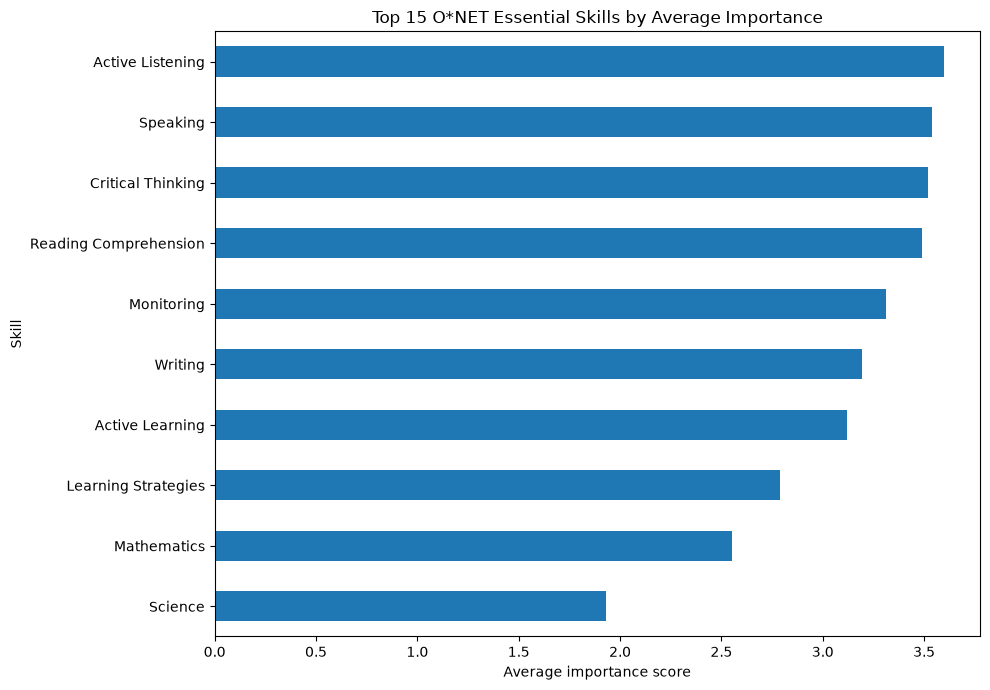

Chart saved to: C:\Users\S_Gayathri\skill-gap-analyzer\reports\top_onet_essential_skills.png


In [7]:

top_skills = (
    onet_importance.groupby("Element Name")["Data Value"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
top_skills.plot(kind="barh")
plt.title("Top 15 O*NET Essential Skills by Average Importance")
plt.xlabel("Average importance score")
plt.ylabel("Skill")
plt.tight_layout()

figure_path = REPORTS_DIR / "top_onet_essential_skills.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", figure_path)


In [8]:

resumes[["ID", "Category", "clean_resume"]].to_csv(
    PROCESSED_DIR / "cleaned_resumes.csv",
    index=False
)

jobs[[
    "job_id", "company_name", "title",
    "description", "skills_desc", "job_text"
]].to_csv(
    PROCESSED_DIR / "cleaned_job_postings_sample.csv",
    index=False
)

job_skills.to_csv(
    PROCESSED_DIR / "cleaned_job_skills.csv",
    index=False
)

onet_importance.to_csv(
    PROCESSED_DIR / "onet_skill_importance.csv",
    index=False
)

software_skills.to_csv(
    PROCESSED_DIR / "onet_software_skills.csv",
    index=False
)

print("Preprocessing completed!")
print("Saved files:")
for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print("-", file.name, f"({file.stat().st_size / 1024:.1f} KB)")


Preprocessing completed!
Saved files:
- cleaned_job_postings_sample.csv (145825.3 KB)
- cleaned_job_skills.csv (3424.5 KB)
- cleaned_resumes.csv (14134.4 KB)
- onet_skill_importance.csv (1117.4 KB)
- onet_software_skills.csv (3474.2 KB)
